# Observed trends and sex contrasts

Dates are irregular: 2000, 2010, 2015, 2019–2023. We report endpoint changes and deviation from the observed 2019 value, not extrapolated counterfactuals or forecasts. WLD uses aggregate age-specific counts and populations and the broad-bin WHO2026 method for both measures.

In [1]:
from pathlib import Path
import json
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "contracts/organs.json").exists())
sys.path.insert(0, str(root / "pipeline/src"))
import pandas as pd
from IPython.display import display, Markdown
from visceral_pipeline.analysis.data import CACHE, load_inputs, load_results
from visceral_pipeline.analysis import comparisons, sensitivity, clustering, plots
inputs, frames = load_inputs(), load_results()
meta = json.loads((CACHE / "metadata.json").read_text())
pd.set_option("display.max_rows", 65)
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 140)


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\louis\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


year,measure,location,organ,change_2000_2019,change_2019_2020,change_2019_2021,change_2000_2023
5580,dalys,WLD,bladder,-19.166665,0.453747,-0.757052,-20.254653
5581,dalys,WLD,blood_immune,-15.929461,-0.558183,-2.305146,-20.692381
5582,dalys,WLD,bones_joints,3.178601,-0.364414,-0.551649,0.644983
5583,dalys,WLD,brain,-19.249034,-2.856026,-0.012237,-19.874943
5584,dalys,WLD,breast,-6.823964,0.825073,1.020167,-4.500187
5585,dalys,WLD,colon_rectum,-15.042561,-0.365758,-0.636548,-15.734010
5586,dalys,WLD,congenital,-13.868401,-2.126336,-1.938935,-17.016560
5587,dalys,WLD,diabetes_endocrine,18.358433,-0.065100,3.135389,21.580296
5588,dalys,WLD,ears,2.287705,0.017791,0.229904,2.844191
5589,dalys,WLD,esophagus,-22.540972,1.269864,2.292158,-19.394751


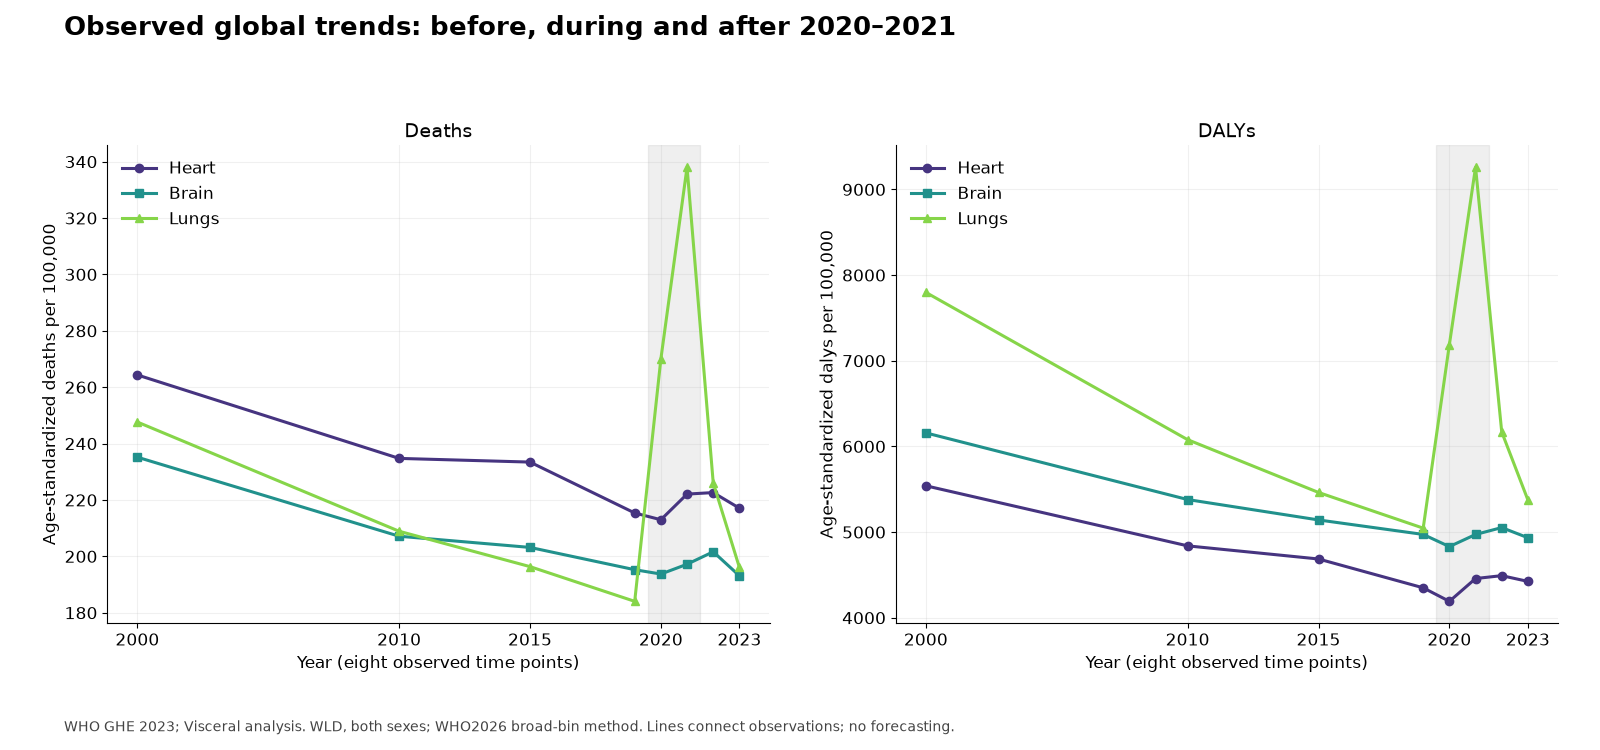

year                        change_2000_2019  change_2019_2020  change_2019_2021
measure organ                                                                   
dalys   bladder       0.05        -41.203844        -14.026830        -24.794288
                      0.50         -7.046529          2.018732          1.406891
                      0.95         29.603026         13.589898         22.019620
        blood_immune  0.05        -37.754712         -9.918352        -11.939705
                      0.50        -18.353370         -1.087588         -3.893053
...                                      ...               ...               ...
deaths  thyroid       0.50          3.389000          0.911113          2.645447
                      0.95         55.939281         24.993296         24.469973
        uterus_cervix 0.05        -44.326536        -14.042976        -23.401223
                      0.50        -11.415962          0.135830          0.121116
                      0.95         23.129456         14.174712         10.104540

[186 rows x 3 columns]

year,measure,location,organ,change_2000_2019,change_2019_2020,change_2019_2021
3,dalys,AFG,brain,-32.138457,-2.020274,-12.241365
2607,dalys,JPN,brain,-11.742058,-1.382879,0.084079
3723,dalys,NGA,brain,-16.889514,6.911995,5.284560
5335,dalys,UKR,brain,-27.486775,-3.088979,-10.454062
5397,dalys,USA,brain,4.303010,4.148877,1.518886
12,dalys,AFG,heart,-25.449471,-5.834481,-14.559123
2616,dalys,JPN,heart,-21.699246,-1.082478,1.295461
3732,dalys,NGA,heart,-15.023159,14.700367,11.788920
5344,dalys,UKR,heart,-18.488733,-3.290925,-11.906426
5406,dalys,USA,heart,-38.076682,6.641717,7.041869


In [2]:
changes = comparisons.period_changes(inputs['burden'])
display(changes.query("location=='WLD'").drop(columns=[2000,2010,2015,2019,2020,2021,2022,2023]))
plots.display_figure(plots.trends(frames,meta))
display(changes.query("location!='WLD'").groupby(['measure','organ'])[['change_2000_2019','change_2019_2020','change_2019_2021']].quantile([.05,.5,.95]))
display(changes.query("location in ['JPN','NGA','USA','UKR','AFG'] and organ in ['heart','brain','lungs']")[['measure','location','organ','change_2000_2019','change_2019_2020','change_2019_2021']].sort_values(['measure','organ','location']))

## COVID-19 accounting

COVID-19 is mapped to lungs for its respiratory presentation while systemic effects are acknowledged. Standardization is linear, so the total lung change separates into COVID and other mapped causes. COVID can exceed 100% of the **net** increase when other mapped lung causes decline. This is arithmetic attribution, not a claim that COVID caused all observed changes in other diseases.

In [3]:
display(comparisons.pandemic_decomposition(inputs['burden'],inputs['covid']))

,measure,year,metric,baseline,observed,change,cause_change,other_change,cause_share_of_net_change_percent
0,deaths,2020,count,9.548816e+06,1.433089e+07,4.782069e+06,5.293270e+06,-5.112012e+05,110.689959
1,deaths,2020,ageStdRate,1.840449e+02,2.700262e+02,8.598133e+01,9.987214e+01,-1.389081e+01,116.155615
2,deaths,2021,count,9.548816e+06,1.865105e+07,9.102236e+06,9.438482e+06,-3.362455e+05,103.694098
3,deaths,2021,ageStdRate,1.840449e+02,3.380358e+02,1.539910e+02,1.687698e+02,-1.477886e+01,109.597226
4,dalys,2020,count,3.285141e+08,4.670530e+08,1.385389e+08,1.557885e+08,-1.724956e+07,112.451055
5,dalys,2020,ageStdRate,5.045939e+03,7.188451e+03,2.142513e+03,2.482505e+03,-3.399927e+02,115.868876
6,dalys,2021,count,3.285141e+08,6.136093e+08,2.850952e+08,2.968047e+08,-1.170942e+07,104.107196
7,dalys,2021,ageStdRate,5.045939e+03,9.259538e+03,4.213600e+03,4.532399e+03,-3.187992e+02,107.565959


## Sex contrasts

Male/female ASDR ratios exclude prostate, testes, uterus/cervix, ovaries and breast (consistent exclusion despite male breast disease), plus the inseparable maternal/neonatal group. Zero female denominators are undefined, not zero ratios. Global estimates use broad bins while country death estimates use WHO fine-age rates; the distinction is labeled. Tiny death denominators, particularly sensory causes, can yield unstable ratios. These descriptive contrasts do not establish biological, exposure or care mechanisms.

,measure,organ,world_ratio,n,p05,p25,median,p75,p95
0,dalys,bladder,3.734318,185,1.286732,2.110128,3.189682,4.867973,8.679360
1,dalys,blood_immune,0.823028,185,0.577725,0.734503,0.881598,1.060906,1.271084
2,dalys,bones_joints,0.669164,185,0.611829,0.657936,0.698899,0.725495,0.776185
3,dalys,brain,1.130001,185,0.796157,0.917127,1.042466,1.160253,1.425154
4,dalys,colon_rectum,1.498279,185,0.980778,1.222761,1.406232,1.599517,1.959879
5,dalys,congenital,1.154702,185,0.999875,1.124988,1.193590,1.247812,1.334230
6,dalys,diabetes_endocrine,1.215241,185,0.833301,1.041026,1.232687,1.368410,1.598595
7,dalys,ears,1.089864,185,1.027543,1.047188,1.084318,1.129135,1.194041
8,dalys,esophagus,3.076580,185,1.079639,1.607465,2.827763,5.025404,16.466275
9,dalys,eyes,0.850012,185,0.761929,0.806560,0.854637,0.916734,1.050940


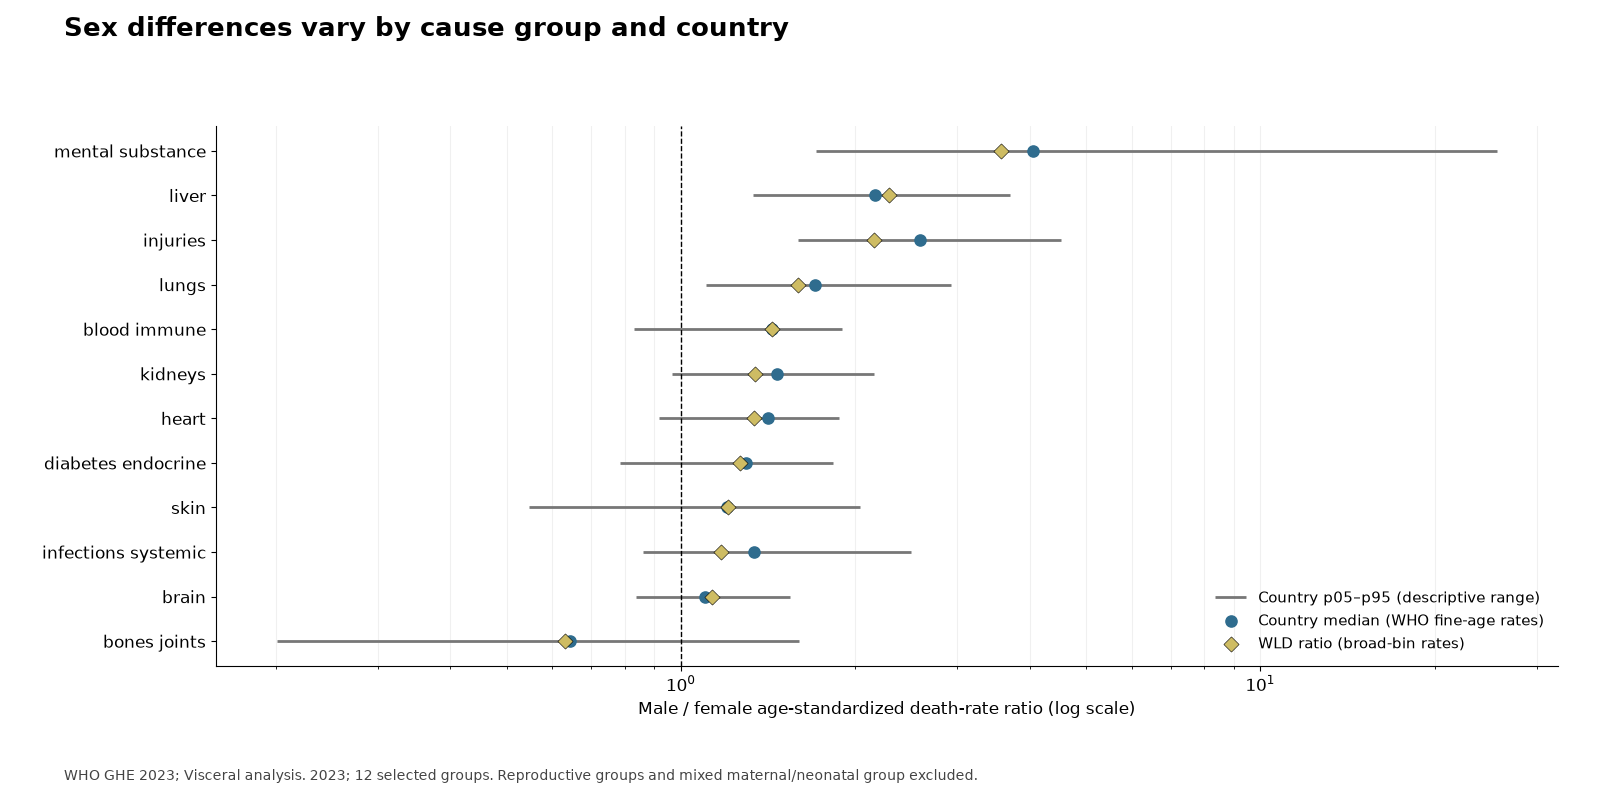

In [4]:
ratios, summary = comparisons.sex_ratios(inputs['burden'])
display(summary)
plots.display_figure(plots.sex(frames,meta))